# 8. K-means Clustering / K-means Kümeleme

**English theory:** [Classification](../Classification.md) · **Türkçe teori:** [Sınıflandırma](../Classification.tr.md) · [Notebook index / dizin](../README.md)

Discover groups in 3,000 synthetic observations without class labels. Implement Lloyd's updates, then inspect K-means++, inertia, silhouette and a non-convex failure case.

**Türkçe:** Bu bölüm sınıflandırma değil, gözetimsiz kümelemedir. Etiket/accuracy yerine geometrik amaç fonksiyonu ve kümelerin ayrışması incelenir.

Run **Restart Kernel → Run All** to reproduce every output. Each notebook starts from raw local data and has no dependency on another notebook's variables. Saved tables and figures are actual executed outputs.

**Türkçe:** Sonuçları yeniden üretmek için çekirdeği yeniden başlatıp bütün hücreleri sırayla çalıştırın. Veri dosyaları repoda bulunur; başka bir notebook'un önceden çalıştırılması gerekmez.

In [1]:
from pathlib import Path
import json
import platform
import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, JSON

# Works when launched from this folder, Classification/, or the repository root.
candidates = [Path.cwd(), *Path.cwd().parents]
CLASSIFICATION_DIR = next(
    folder for base in candidates for folder in (base, base / "Classification")
    if (folder / "Classification.md").is_file()
    and (folder / "datasets" / "data.csv").is_file()
)
SEED = 42
np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.max_columns", 12)
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (9, 4.5), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "font.size": 11})
versions = {"Python": platform.python_version(), "NumPy": np.__version__,
            "pandas": pd.__version__, "SciPy": scipy.__version__,
            "scikit-learn": sklearn.__version__, "Matplotlib": matplotlib.__version__}
display(pd.Series(versions, name="Environment"))

Python          3.10.11
NumPy            1.26.4
pandas            2.3.3
SciPy            1.13.1
scikit-learn      1.7.2
Matplotlib       3.10.9
Name: Environment, dtype: object

In [2]:
def make_clouds(seed=42):
    rng = np.random.default_rng(seed)
    return np.vstack([rng.normal(loc=mean, scale=5, size=(1000, 2))
                      for mean in [(25, 25), (55, 60), (55, 15)]])

X = make_clouds(SEED)
assert X.shape == (3000, 2) and np.isfinite(X).all()
print("Unlabelled data shape:", X.shape)
display(pd.DataFrame(X, columns=["x1", "x2"]).describe())

Unlabelled data shape: (3000, 2)


,x1,x2
count,3000.000000,3000.000000
mean,44.948739,33.300857
std,15.182851,20.022397
min,10.177356,-6.945573
25%,27.884693,17.310634
50%,51.751977,25.312297
75%,56.689272,56.652558
max,71.355131,75.297656


## Assign, then average / Ata, sonra ortala

$$J=\sum_i\lVert x_i-\mu_{c_i}\rVert^2,\qquad
c_i=\arg\min_k\lVert x_i-\mu_k\rVert^2,\qquad
\mu_k=\frac1{|C_k|}\sum_{i\in C_k}x_i.$$

For fixed centers, choosing the nearest center minimizes each row's contribution. For fixed assignments, differentiating the squared loss gives $2|C_k|\mu_k-2\sum_{i\in C_k}x_i=0$, hence the mean. Alternating the two cannot increase the objective, but may reach a local minimum. The code retains an empty cluster's previous center; real implementations use stronger reinitialization rules.

**Türkçe:** İki alt problem de tek başına çözülebilir: merkez sabitken en yakına ata, atama sabitken ortalamayı bul. K-means'in küme merkezini medyan yerine ortalamayla güncellemesi kareli uzaklığın türevinden gelir.

Lloyd iterations: 5; loss 2,480,276.97 → 150,669.43


,centroid_x1,centroid_x2
0,24.628073,24.814334
1,55.115444,15.009042
2,55.072211,60.088999


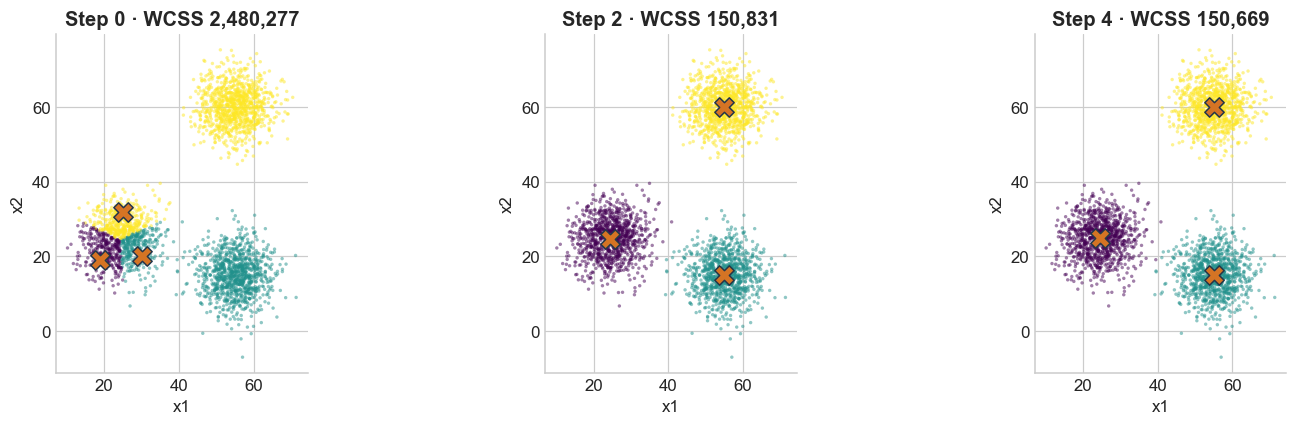

In [3]:
def lloyd(X, initial_centers, max_iter=100):
    centers = np.array(initial_centers, dtype=float, copy=True)
    history = []
    for _ in range(max_iter):
        squared_distances = ((X[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2)
        labels = squared_distances.argmin(axis=1)
        updated = np.array([X[labels == k].mean(axis=0) if np.any(labels == k) else centers[k]
                            for k in range(len(centers))])
        loss = ((X - centers[labels]) ** 2).sum()
        history.append({"centers": centers.copy(), "labels": labels.copy(), "loss": float(loss)})
        if np.allclose(centers, updated, rtol=0, atol=1e-10):
            break
        centers = updated
    return centers, labels, history

initial_centers = [[19, 19], [30, 20], [25, 32]]
centers, labels, history = lloyd(X, initial_centers)
losses = np.array([row["loss"] for row in history])
assert np.all(np.diff(losses) <= 1e-8)
assert np.allclose(centers, np.array([X[labels == k].mean(axis=0) for k in range(3)]))
print(f"Lloyd iterations: {len(history)}; loss {losses[0]:,.2f} → {losses[-1]:,.2f}")
display(pd.DataFrame(centers, columns=["centroid_x1", "centroid_x2"]))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, step in zip(axes, [0, 2, len(history) - 1]):
    state = history[step]
    ax.scatter(*X.T, c=state["labels"], cmap="viridis", s=5, alpha=.5, linewidths=0, rasterized=True)
    ax.scatter(*state["centers"].T, marker="X", c="#D57424", edgecolors="#25364A", s=160)
    ax.set(title=f"Step {step} · WCSS {state['loss']:,.0f}", xlabel="x1", ylabel="x2", aspect="equal")
plt.tight_layout()
plt.show()

## Library model and choosing K / Kütüphane modeli ve K seçimi

K-means++ spreads starting centers; `n_init=20` tries 20 initializations and retains the smallest inertia. Inertia is WCSS, not an accuracy. Increasing K cannot increase the optimal WCSS, so an elbow is a diminishing-returns judgment, not a proof of a true K.

Silhouette for a row is `(b-a)/max(a,b)`: `a` is its mean distance to its own cluster and `b` the smallest mean distance to another cluster. Values near 1 indicate separation, around 0 overlap, below 0 possible misassignment. Here silhouette is estimated on a fixed 1,500-row subsample for speed. Both coordinates have the same synthetic units; arbitrary scaling would change the intended geometry.

**Türkçe:** Dirsek maliyetin ne kadar azaldığına, silhouette ayrışmaya bakar. Küme numaralarının sırası bir anlam taşımaz; farklı çalıştırmalar aynı gruplara farklı numara verebilir.

,K,inertia,silhouette
0,1,1.893615e+06,NaN
1,2,6.634807e+05,0.629463
2,3,1.506694e+05,0.744410
3,4,1.336990e+05,0.597592
4,5,1.167997e+05,0.464937
5,6,1.005389e+05,0.313996
6,7,8.958929e+04,0.322543
7,8,7.902818e+04,0.331350
8,9,6.934135e+04,0.327481
9,10,6.442681e+04,0.318785


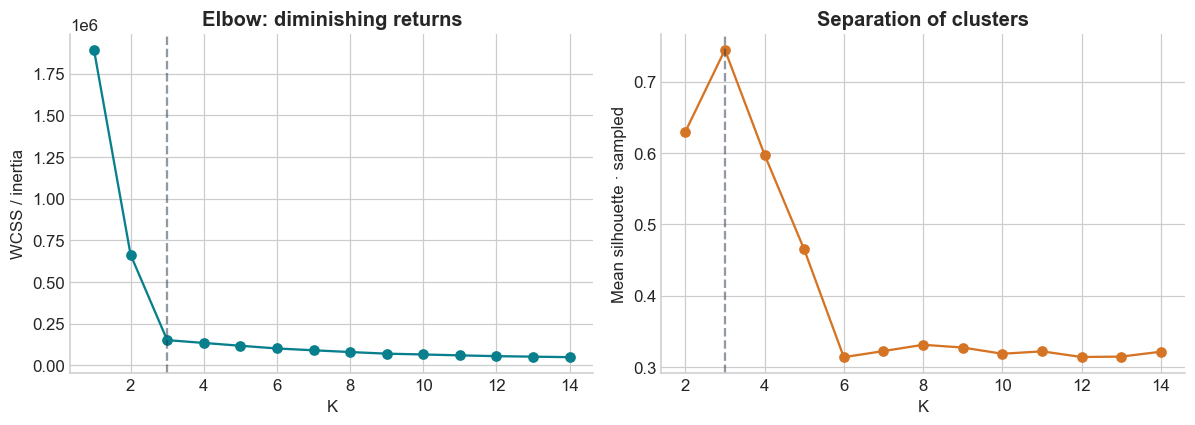

In [4]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

models = {k: KMeans(n_clusters=k, init="k-means++", n_init=20, random_state=SEED).fit(X)
          for k in range(1, 15)}
silhouettes = {k: silhouette_score(X, models[k].labels_, sample_size=1500, random_state=SEED)
               for k in range(2, 15)}
model = models[3]
manual_inertia = np.sum((X - model.cluster_centers_[model.labels_]) ** 2)
assert np.isclose(manual_inertia, model.inertia_)
selection = pd.DataFrame({"K": list(models), "inertia": [m.inertia_ for m in models.values()],
                          "silhouette": [silhouettes.get(k, np.nan) for k in models]})
display(selection)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(selection.K, selection.inertia, "o-", color="#087F8C")
axes[0].set(xlabel="K", ylabel="WCSS / inertia", title="Elbow: diminishing returns")
axes[1].plot(list(silhouettes), list(silhouettes.values()), "o-", color="#D57424")
axes[1].set(xlabel="K", ylabel="Mean silhouette · sampled", title="Separation of clusters")
for ax in axes:
    ax.axvline(3, color="#25364A", linestyle="--", alpha=.5)
plt.tight_layout()
plt.show()

## When the geometry is wrong / Geometri uygun değilse

K-means produces convex Voronoi regions around centroids. Even knowing `K=2` cannot make it recover two intertwined moons reliably. Outliers, unequal density and unequal feature units can also distort the result. Cluster interpretation requires domain knowledge.

**Türkçe:** K'nin doğru olması tek başına yeterli değildir. Amaç fonksiyonu uzun, kıvrımlı veya farklı yoğunlukta gruplar için uygun olmayabilir.

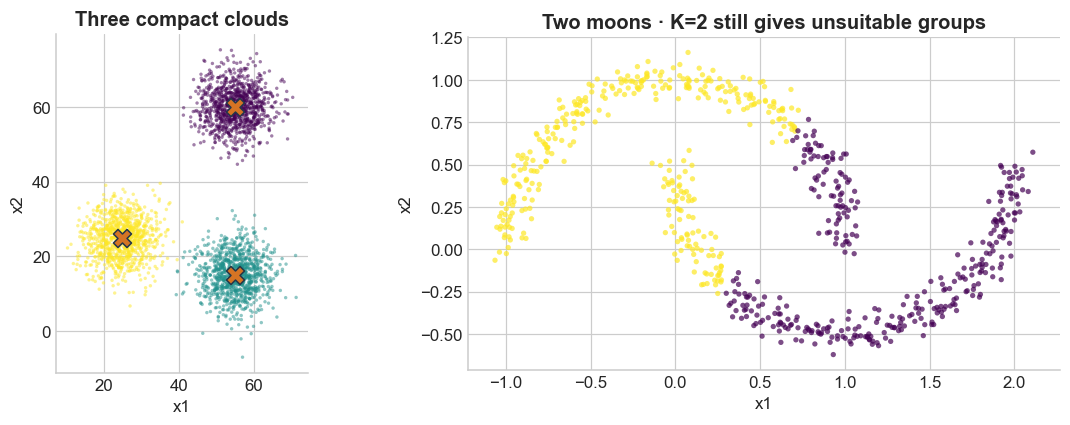

In [5]:
from sklearn.datasets import make_moons

moons, _ = make_moons(n_samples=700, noise=.055, random_state=SEED)
moon_labels = KMeans(n_clusters=2, n_init=20, random_state=SEED).fit_predict(moons)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(*X.T, c=model.labels_, cmap="viridis", s=5, alpha=.5, linewidths=0)
axes[0].scatter(*model.cluster_centers_.T, marker="X", s=140, c="#D57424", edgecolors="#25364A")
axes[0].set(title="Three compact clouds", xlabel="x1", ylabel="x2", aspect="equal")
axes[1].scatter(*moons.T, c=moon_labels, cmap="viridis", s=12, alpha=.7, linewidths=0)
axes[1].set(title="Two moons · K=2 still gives unsuitable groups", xlabel="x1", ylabel="x2", aspect="equal")
plt.tight_layout()
plt.show()

## Measured result / Ölçülen sonuç

This summary is produced by the cells above; the runner also collects it in `Classification/notebook_results.json`. A single split is an educational experiment, not a guarantee for a different dataset.

**Türkçe:** Aşağıdaki değerler bu notebook'un gerçek çıktısıdır. Farklı veri veya ayrımlarda aynı sonuç garanti edilmez.

In [6]:
results = {"chapter": 8, "rows": len(X), "K": 3, "inertia": float(model.inertia_),
           "sampled_silhouette": float(silhouettes[3]), "centers": model.cluster_centers_.tolist(),
           "cluster_sizes": np.bincount(model.labels_).tolist(),
           "lloyd_steps": len(history), "lloyd_final_loss": float(losses[-1]),
           "selection": selection.replace({np.nan: None}).to_dict(orient="records")}
results["versions"] = versions
display(JSON(results, expanded=True))

<IPython.core.display.JSON object>